In [2]:
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit_ibm_runtime import SamplerV2 as Sampler,QiskitRuntimeService
import numpy as np

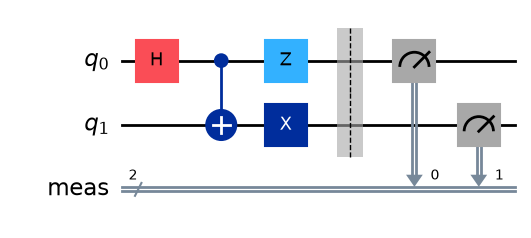

In [3]:
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.x(1)
qc.z(0)

qc.measure_all()

qc.draw('mpl')

In [4]:
import os
from dotenv import load_dotenv

load_dotenv()

API_KEY = os.getenv("QISKIT_API_KEY")

In [6]:
QiskitRuntimeService.save_account(channel='ibm_quantum_platform',token=API_KEY,overwrite=True,set_as_default=True)
service = QiskitRuntimeService(channel='ibm_quantum_platform')

service = QiskitRuntimeService()

backend = service.least_busy(operational=True,simulator=False,min_num_qubits=127)

print(backend.name)

qiskit_runtime_service.__init__:WARNING:2026-10-11 22:11:00,094: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: qiskit learning. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.__init__:WARNING:2026-10-11 22:11:05,298: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: qiskit learning. If you need a specific instance set it explicitly either by using a saved account with a saved default i

ibm_fez


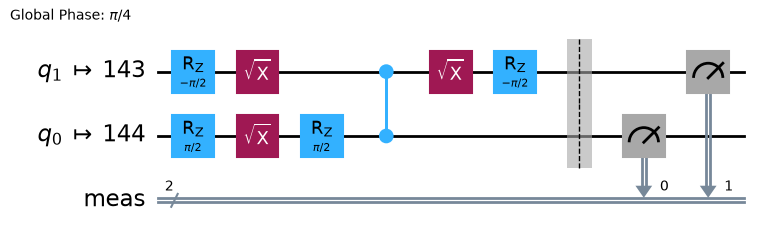

In [7]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target,optimization_level=3)
qc_isa = pm.run(qc)

qc_isa.draw('mpl')

In [9]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(mode=backend)

C:\Users\Admin\AppData\Local\Temp\ipykernel_18676\870989429.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)
